In [1]:

%cd /content

!git clone https://github.com/CecyLeura/EventBot.git

%cd /content/EventBot


/content
Cloning into 'EventBot'...
remote: Enumerating objects: 47, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 47 (delta 8), reused 14 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (47/47), 409.64 KiB | 4.02 MiB/s, done.
Resolving deltas: 100% (8/8), done.
/content/EventBot


In [2]:

from pathlib import Path

carpetas = [
    "data/texto",
    "data/imagenes",
    "resultados/avance2",
    "modelos"
]

for carpeta in carpetas:
    Path(carpeta).mkdir(parents=True, exist_ok=True)

print("Carpetas del Avance 2 creadas correctamente")


Carpetas del Avance 2 creadas correctamente


In [3]:

!ls


data	    main.py  notebooks	requirements.txt  src
evidencias  modelos  README.md	resultados


In [4]:

from pathlib import Path

ruta_proyecto = Path("/content/EventBot")
ruta_src = ruta_proyecto / "src"

print("MODULOS ACTUALES DE EVENTBOT")
print("=" * 45)

for archivo in sorted(ruta_src.glob("*.py")):
    print(f"- {archivo.name}")

print("\nARCHIVOS DE DATOS")
print("=" * 45)

for archivo in sorted((ruta_proyecto / "data").rglob("*")):
    if archivo.is_file():
        print(f"- {archivo.relative_to(ruta_proyecto)}")


MODULOS ACTUALES DE EVENTBOT
- __init__.py
- base_conocimiento.py
- configuracion.py
- detector_intenciones.py
- eventbot.py
- gestor_conversacion.py
- procesador_texto.py

ARCHIVOS DE DATOS
- data/disponibilidad.json
- data/informacion_salon.json
- data/paquetes.json
- data/promociones.json


In [5]:

from pathlib import Path

ruta = Path("/content/EventBot/src")

archivos = [
    "configuracion.py",
    "procesador_texto.py",
    "detector_intenciones.py"
]

for nombre in archivos:
    archivo = ruta / nombre

    print("\n" + "=" * 60)
    print("ARCHIVO:", nombre)
    print("=" * 60)

    print(archivo.read_text(encoding="utf-8"))



ARCHIVO: configuracion.py

# ============================================
# EVENTBOT - CONFIGURACIÓN DEL PROYECTO
# ============================================

from dataclasses import dataclass
from pathlib import Path


@dataclass
class ConfiguracionEventBot:

    nombre_proyecto: str = "EventBot"
    nombre_salon: str = "Salón Destellos"

    ruta_proyecto: str = "/content/EventBot"

    idioma: str = "es"

    capacidad_minima: int = 50
    capacidad_maxima: int = 300

    @property
    def ruta_data(self):
        return Path(self.ruta_proyecto) / "data"

    @property
    def ruta_evidencias(self):
        return Path(self.ruta_proyecto) / "evidencias"

    @property
    def ruta_resultados(self):
        return Path(self.ruta_proyecto) / "resultados"

    def crear_directorios(self):
        self.ruta_data.mkdir(parents=True, exist_ok=True)
        self.ruta_evidencias.mkdir(parents=True, exist_ok=True)
        self.ruta_resultados.mkdir(parents=True, exist_ok=True)


ARCHIVO:

In [6]:

%%writefile /content/EventBot/src/preprocesador_nlp.py

# ============================================
# EVENTBOT - PREPROCESADOR NLP
# AVANCE DE PROYECTO 2
# ============================================

import re
import unicodedata

from nltk.tokenize import wordpunct_tokenize
from nltk.stem.snowball import SnowballStemmer


class PreprocesadorNLP:

    def __init__(self):

        self.stemmer = SnowballStemmer("spanish")

        # Lista personalizada de palabras vacias
        self.stopwords = {
            "el", "la", "los", "las",
            "un", "una", "unos", "unas",
            "de", "del", "al", "en",
            "por", "para", "con",
            "me", "te", "se", "le",
            "mi", "tu", "su",
            "que", "como", "cual",
            "es", "son", "ser",
            "puedes", "podrias",
            "favor", "quiero", "quisiera"
        }

    def normalizar(self, texto):

        if not isinstance(texto, str):
            raise TypeError("El texto debe ser una cadena.")

        texto = texto.lower().strip()

        texto = unicodedata.normalize("NFD", texto)

        texto = "".join(
            caracter
            for caracter in texto
            if unicodedata.category(caracter) != "Mn"
        )

        texto = re.sub(r"[^a-z0-9\s]", " ", texto)

        texto = re.sub(r"\s+", " ", texto).strip()

        return texto

    def tokenizar(self, texto):

        texto = self.normalizar(texto)

        return wordpunct_tokenize(texto)

    def eliminar_stopwords(self, tokens):

        return [
            token for token in tokens
            if token not in self.stopwords
        ]

    def aplicar_stemming(self, tokens):

        return [
            self.stemmer.stem(token)
            for token in tokens
        ]

    def procesar(self, texto):

        normalizado = self.normalizar(texto)

        tokens = self.tokenizar(texto)

        relevantes = self.eliminar_stopwords(tokens)

        raices = self.aplicar_stemming(relevantes)

        return {
            "texto_original": texto,
            "texto_normalizado": normalizado,
            "tokens": tokens,
            "tokens_relevantes": relevantes,
            "tokens_stemming": raices,
            "texto_procesado": " ".join(raices)
        }


Writing /content/EventBot/src/preprocesador_nlp.py


In [7]:

import sys

sys.path.insert(0, "/content/EventBot")

from src.preprocesador_nlp import PreprocesadorNLP

preprocesador = PreprocesadorNLP()

consulta = "¿Cuáles son los precios de los paquetes para bodas?"

resultado = preprocesador.procesar(consulta)

for clave, valor in resultado.items():
    print(f"{clave}: {valor}")


texto_original: ¿Cuáles son los precios de los paquetes para bodas?
texto_normalizado: cuales son los precios de los paquetes para bodas
tokens: ['cuales', 'son', 'los', 'precios', 'de', 'los', 'paquetes', 'para', 'bodas']
tokens_relevantes: ['cuales', 'precios', 'paquetes', 'bodas']
tokens_stemming: ['cual', 'preci', 'paquet', 'bod']
texto_procesado: cual preci paquet bod


In [8]:

import pandas as pd
from pathlib import Path

ejemplos = {
    "saludo": [
        "Hola", "Buenos días", "Buenas tardes",
        "Buenas noches", "Hola qué tal",
        "Qué onda", "Saludos", "Buen día",
        "Hola necesito información", "Hey buenas"
    ],
    "despedida": [
        "Adiós", "Hasta luego", "Nos vemos",
        "Hasta pronto", "Chao", "Bye",
        "Que tengas buen día", "Hasta mañana",
        "Me despido", "Gracias hasta luego"
    ],
    "agradecimiento": [
        "Gracias", "Muchas gracias", "Te agradezco",
        "Mil gracias", "Gracias por la información",
        "Muy amable", "Se agradece",
        "Gracias por tu ayuda", "Perfecto gracias",
        "Excelente muchas gracias"
    ],
    "ubicacion": [
        "Dónde están ubicados", "Cuál es su dirección",
        "Dónde se encuentra el salón", "Cómo llego",
        "En qué zona están", "Me compartes la ubicación",
        "Dónde queda Salón Destellos", "Cuál es la dirección del lugar",
        "Me puedes decir dónde están", "Dónde los encuentro"
    ],
    "horarios": [
        "Cuál es su horario", "A qué hora abren",
        "A qué hora cierran", "Qué horarios manejan",
        "En qué horario atienden", "Cuáles son sus horas de atención",
        "Abren los domingos", "Qué días atienden",
        "Hasta qué hora están abiertos", "Cuál es el horario del salón"
    ],
    "paquetes": [
        "Qué paquetes tienen", "Qué incluye el paquete Premium",
        "Cuáles son sus paquetes", "Qué servicios ofrecen",
        "Qué contiene el paquete Esencial",
        "Me explicas los paquetes disponibles",
        "Qué incluye el paquete Diamante",
        "Cuáles son los servicios del salón",
        "Qué opciones de paquetes ofrecen",
        "Qué incluye el paquete Clásico"
    ],
    "costos": [
        "Cuánto cuesta el salón", "Cuál es el precio del paquete Premium",
        "Cuánto cobran por un evento", "Me puedes cotizar",
        "Cuáles son sus precios", "Cuál es el costo del paquete Diamante",
        "Cuánto vale una reservación", "Necesito un presupuesto",
        "Cuánto cuesta el paquete Esencial",
        "Qué precio tiene el paquete Clásico"
    ],
    "promociones": [
        "Tienen promociones", "Hay descuentos disponibles",
        "Qué ofertas manejan", "Tienen alguna promoción",
        "Ofrecen descuentos", "Hay alguna oferta especial",
        "Qué promociones tienen este mes",
        "Tienen promos para bodas", "Hay descuentos para eventos",
        "Manejan precios promocionales"
    ],
    "disponibilidad": [
        "Tienen disponibilidad", "Está libre el salón",
        "Qué fechas tienen disponibles",
        "Hay lugar para diciembre",
        "Está disponible el 15 de noviembre",
        "Puedo consultar una fecha",
        "Tienen fechas libres para bodas",
        "Quiero saber si hay disponibilidad",
        "Está ocupado el sábado",
        "Qué días están disponibles"
    ],
    "reservacion": [
        "Cómo puedo reservar", "Quiero hacer una reservación",
        "Cómo aparto una fecha", "Qué necesito para reservar",
        "Puedo apartar el salón", "Cómo se hace una reserva",
        "Cuánto anticipo debo dar",
        "Quiero confirmar una reservación",
        "Cuál es el proceso para reservar",
        "Cómo puedo contratar el salón"
    ],
    "capacidad": [
        "Cuántas personas caben", "Cuál es la capacidad",
        "Aceptan 200 invitados", "Pueden recibir 350 personas",
        "Cuál es el aforo máximo", "Caben 150 invitados",
        "Cuántos invitados admite el salón",
        "Tienen capacidad para 100 personas",
        "Puedo organizar un evento para 300 invitados",
        "Cuál es el mínimo de invitados"
    ],
    "amenidades": [
        "Tienen estacionamiento", "El salón tiene clima",
        "Cuentan con sonido", "Incluyen mesas y sillas",
        "Tienen pista de baile", "Qué amenidades ofrecen",
        "Hay iluminación especial", "Cuentan con aire acondicionado",
        "Tienen equipo de audio", "El salón incluye mobiliario"
    ],
    "tipos_eventos": [
        "Organizan bodas", "Puedo celebrar mis XV años",
        "Hacen bautizos", "Aceptan graduaciones",
        "Qué tipos de eventos realizan",
        "Puedo organizar un cumpleaños",
        "Hacen fiestas de aniversario",
        "Organizan eventos familiares",
        "Puedo celebrar una quinceañera",
        "Qué celebraciones se pueden realizar"
    ]
}

registros = [
    {"texto": texto, "intencion": intencion}
    for intencion, consultas in ejemplos.items()
    for texto in consultas
]

df = pd.DataFrame(registros)

ruta = Path("/content/EventBot/data/texto")
ruta.mkdir(parents=True, exist_ok=True)

archivo = ruta / "intenciones_entrenamiento.csv"

df.to_csv(archivo, index=False, encoding="utf-8-sig")

print("Dataset creado correctamente")
print("Total de ejemplos:", len(df))
print("Total de intenciones:", df["intencion"].nunique())
print("\nEjemplos por intención:")
print(df["intencion"].value_counts().sort_index())
print("\nPrimeras consultas:")
print(df.head())


Dataset creado correctamente
Total de ejemplos: 130
Total de intenciones: 13

Ejemplos por intención:
intencion
agradecimiento    10
amenidades        10
capacidad         10
costos            10
despedida         10
disponibilidad    10
horarios          10
paquetes          10
promociones       10
reservacion       10
saludo            10
tipos_eventos     10
ubicacion         10
Name: count, dtype: int64

Primeras consultas:
           texto intencion
0           Hola    saludo
1    Buenos días    saludo
2  Buenas tardes    saludo
3  Buenas noches    saludo
4   Hola qué tal    saludo


In [9]:

%%writefile /content/EventBot/src/clasificador_intenciones.py

# ============================================
# EVENTBOT - CLASIFICADOR DE INTENCIONES
# AVANCE DE PROYECTO 2
# ============================================

import joblib
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from src.preprocesador_nlp import PreprocesadorNLP


class ClasificadorIntenciones:

    def __init__(self, random_state=42):

        self.random_state = random_state
        self.preprocesador = PreprocesadorNLP()

        self.pipeline = Pipeline([
            (
                "preprocesamiento",
                FunctionTransformer(
                    self._preprocesar_textos,
                    validate=False
                )
            ),
            (
                "tfidf",
                TfidfVectorizer(
                    ngram_range=(1, 2)
                )
            ),
            (
                "clasificador",
                LinearSVC(
                    random_state=self.random_state,
                    max_iter=5000
                )
            )
        ])

    def _preprocesar_textos(self, textos):

        return [
            self.preprocesador.procesar(texto)[
                "texto_procesado"
            ]
            for texto in textos
        ]

    def entrenar(self, ruta_dataset):

        datos = pd.read_csv(ruta_dataset)

        X = datos["texto"]
        y = datos["intencion"]

        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.30,
            random_state=self.random_state,
            stratify=y
        )

        self.pipeline.fit(X_train, y_train)

        predicciones = self.pipeline.predict(X_test)

        accuracy = accuracy_score(y_test, predicciones)

        reporte = classification_report(
            y_test,
            predicciones,
            zero_division=0,
            output_dict=True
        )

        etiquetas = sorted(y.unique())

        matriz = confusion_matrix(
            y_test,
            predicciones,
            labels=etiquetas
        )

        return {
            "accuracy": accuracy,
            "reporte": reporte,
            "matriz_confusion": matriz,
            "etiquetas": etiquetas,
            "X_test": X_test,
            "y_test": y_test,
            "predicciones": predicciones
        }

    def predecir(self, texto):

        return self.pipeline.predict([texto])[0]

    def guardar_modelo(self, ruta):

        joblib.dump(self.pipeline, ruta)

    def cargar_modelo(self, ruta):

        self.pipeline = joblib.load(ruta)


Writing /content/EventBot/src/clasificador_intenciones.py


In [10]:

import sys

sys.path.insert(0, "/content/EventBot")

from src.clasificador_intenciones import ClasificadorIntenciones

clasificador = ClasificadorIntenciones(random_state=42)

ruta_dataset = (
    "/content/EventBot/data/texto/"
    "intenciones_entrenamiento.csv"
)

resultados_nlp = clasificador.entrenar(ruta_dataset)

print("ENTRENAMIENTO FINALIZADO")
print("=" * 45)

print(
    "Accuracy:",
    round(resultados_nlp["accuracy"], 4)
)

print(
    "Consultas de prueba:",
    len(resultados_nlp["y_test"])
)

print(
    "Intenciones evaluadas:",
    len(resultados_nlp["etiquetas"])
)


ENTRENAMIENTO FINALIZADO
Accuracy: 0.7436
Consultas de prueba: 39
Intenciones evaluadas: 13


In [11]:

import pandas as pd

reporte_df = pd.DataFrame(
    resultados_nlp["reporte"]
).transpose()

print("REPORTE DE CLASIFICACION NLP")
display(reporte_df.round(3))


REPORTE DE CLASIFICACION NLP


,precision,recall,f1-score,support
agradecimiento,1.000,0.667,0.800,3.000
amenidades,0.667,0.667,0.667,3.000
capacidad,1.000,0.333,0.500,3.000
costos,0.000,0.000,0.000,3.000
despedida,0.375,1.000,0.545,3.000
disponibilidad,0.667,0.667,0.667,3.000
horarios,0.667,0.667,0.667,3.000
paquetes,0.600,1.000,0.750,3.000
promociones,1.000,1.000,1.000,3.000
reservacion,1.000,1.000,1.000,3.000


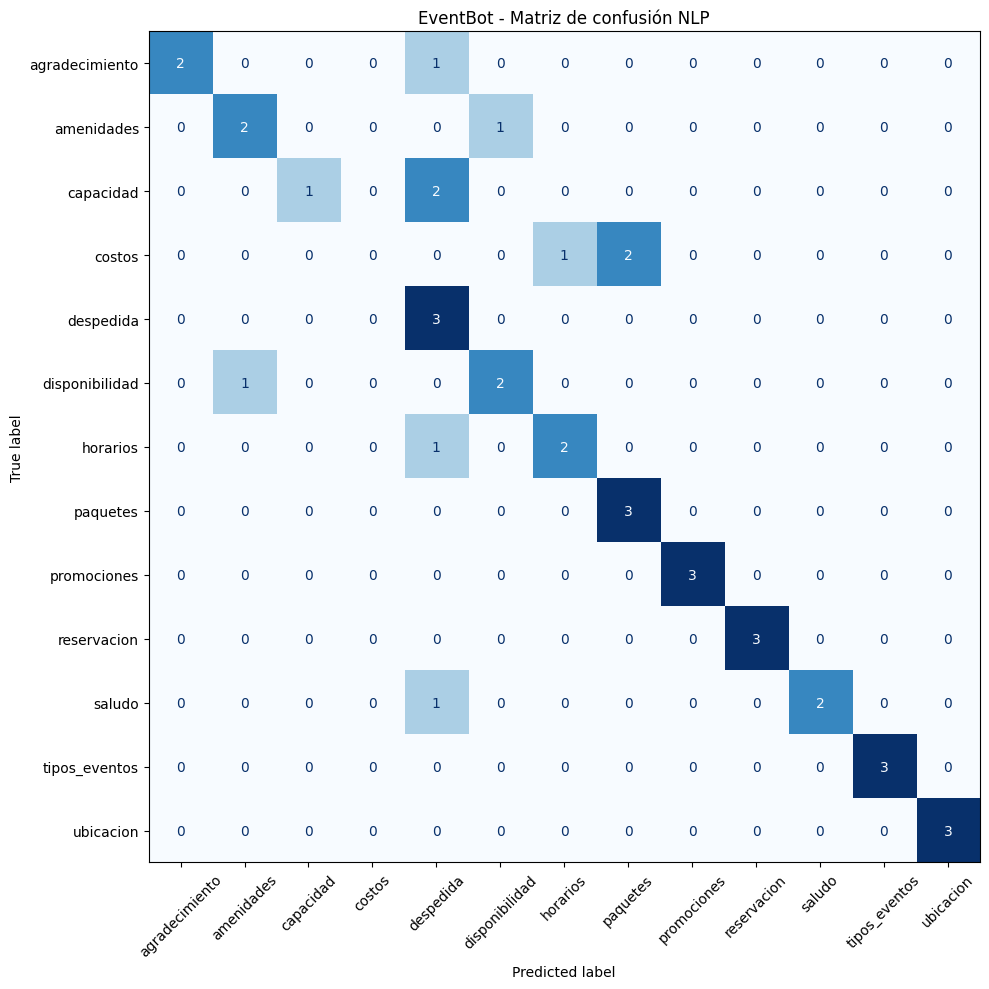

Matriz guardada en: /content/EventBot/resultados/avance2/matriz_confusion_nlp.png


In [12]:

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import ConfusionMatrixDisplay

matriz = resultados_nlp["matriz_confusion"]
etiquetas = resultados_nlp["etiquetas"]

fig, ax = plt.subplots(figsize=(13, 10))

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=etiquetas
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("EventBot - Matriz de confusión NLP")
plt.tight_layout()

ruta_matriz = (
    "/content/EventBot/resultados/avance2/"
    "matriz_confusion_nlp.png"
)

plt.savefig(ruta_matriz, dpi=150, bbox_inches="tight")
plt.show()

print("Matriz guardada en:", ruta_matriz)


In [14]:

comparacion = pd.DataFrame({
    "consulta": resultados_nlp["X_test"].values,
    "intencion_real": resultados_nlp["y_test"].values,
    "intencion_predicha": resultados_nlp["predicciones"]
})

comparacion["correcta"] = (
    comparacion["intencion_real"]
    == comparacion["intencion_predicha"]
)

errores = comparacion[
    comparacion["correcta"] == False
].copy()

print("TOTAL DE ERRORES:", len(errores))

display(
    errores[
        ["consulta", "intencion_real", "intencion_predicha"]
    ]
)

ruta_errores = (
    "/content/EventBot/resultados/avance2/"
    "errores_clasificacion_nlp.csv"
)

errores.to_csv(
    ruta_errores,
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivo guardado:", ruta_errores)


TOTAL DE ERRORES: 10


,consulta,intencion_real,intencion_predicha
1,Tienen disponibilidad,disponibilidad,amenidades
5,Cuál es la capacidad,capacidad,despedida
6,Cuáles son sus precios,costos,horarios
9,Se agradece,agradecimiento,despedida
12,Saludos,saludo,despedida
13,Cuál es el aforo máximo,capacidad,despedida
19,Hasta qué hora están abiertos,horarios,despedida
20,Hay iluminación especial,amenidades,disponibilidad
24,Cuál es el costo del paquete Diamante,costos,paquetes
30,Qué precio tiene el paquete Clásico,costos,paquetes



Archivo guardado: /content/EventBot/resultados/avance2/errores_clasificacion_nlp.csv


In [15]:

import pandas as pd

comparacion = pd.DataFrame({
    "consulta": resultados_nlp["X_test"].values,
    "intencion_real": resultados_nlp["y_test"].values,
    "intencion_predicha": resultados_nlp["predicciones"]
})

errores = comparacion[
    comparacion["intencion_real"] !=
    comparacion["intencion_predicha"]
]

print("TOTAL DE ERRORES:", len(errores))

display(errores)

errores.to_csv(
    "/content/EventBot/resultados/avance2/errores_clasificacion_nlp.csv",
    index=False,
    encoding="utf-8-sig"
)


TOTAL DE ERRORES: 10


,consulta,intencion_real,intencion_predicha
1,Tienen disponibilidad,disponibilidad,amenidades
5,Cuál es la capacidad,capacidad,despedida
6,Cuáles son sus precios,costos,horarios
9,Se agradece,agradecimiento,despedida
12,Saludos,saludo,despedida
13,Cuál es el aforo máximo,capacidad,despedida
19,Hasta qué hora están abiertos,horarios,despedida
20,Hay iluminación especial,amenidades,disponibilidad
24,Cuál es el costo del paquete Diamante,costos,paquetes
30,Qué precio tiene el paquete Clásico,costos,paquetes


In [16]:

from pathlib import Path
import pandas as pd
import json

ruta_resultados = Path(
    "/content/EventBot/resultados/avance2"
)

ruta_resultados.mkdir(
    parents=True,
    exist_ok=True
)

# Guardar el reporte completo
reporte_df = pd.DataFrame(
    resultados_nlp["reporte"]
).transpose()

reporte_df.to_csv(
    ruta_resultados / "reporte_nlp_inicial.csv",
    encoding="utf-8-sig"
)

# Guardar las 39 consultas de prueba
comparacion.to_csv(
    ruta_resultados / "evaluacion_nlp_inicial.csv",
    index=False,
    encoding="utf-8-sig"
)

# Guardar las metricas generales
metricas = {
    "modelo": "TF-IDF + LinearSVC",
    "total_consultas": 130,
    "consultas_prueba": 39,
    "accuracy": float(
        resultados_nlp["accuracy"]
    ),
    "precision_macro": float(
        resultados_nlp["reporte"]["macro avg"]["precision"]
    ),
    "recall_macro": float(
        resultados_nlp["reporte"]["macro avg"]["recall"]
    ),
    "f1_macro": float(
        resultados_nlp["reporte"]["macro avg"]["f1-score"]
    )
}

with open(
    ruta_resultados / "metricas_nlp_inicial.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        metricas,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("Resultados iniciales guardados correctamente")

for archivo in sorted(ruta_resultados.iterdir()):
    print("-", archivo.name)


Resultados iniciales guardados correctamente
- errores_clasificacion_nlp.csv
- evaluacion_nlp_inicial.csv
- matriz_confusion_nlp.png
- metricas_nlp_inicial.json
- reporte_nlp_inicial.csv


In [17]:

import pandas as pd
from pathlib import Path

ruta_base = Path("/content/EventBot")
ruta_datos = ruta_base / "data/texto"

# Cargar el dataset original
datos = pd.read_csv(
    ruta_datos / "intenciones_entrenamiento.csv"
)

# Recuperar las consultas de prueba
evaluacion = pd.read_csv(
    ruta_base /
    "resultados/avance2/evaluacion_nlp_inicial.csv"
)

# Identificar las consultas reservadas para evaluación
consultas_prueba = set(
    zip(
        evaluacion["consulta"],
        evaluacion["intencion_real"]
    )
)

# Separar entrenamiento y prueba
entrenamiento = datos[
    ~datos.apply(
        lambda fila: (
            fila["texto"],
            fila["intencion"]
        ) in consultas_prueba,
        axis=1
    )
].copy()

prueba = evaluacion[
    ["consulta", "intencion_real"]
].rename(
    columns={
        "consulta": "texto",
        "intencion_real": "intencion"
    }
).copy()

# Validar que no existan consultas compartidas
assert len(entrenamiento) == 91
assert len(prueba) == 39

assert set(entrenamiento["texto"]).isdisjoint(
    set(prueba["texto"])
), "Hay consultas repetidas entre entrenamiento y prueba"

# Guardar conjuntos separados
entrenamiento.to_csv(
    ruta_datos / "entrenamiento_nlp_inicial.csv",
    index=False,
    encoding="utf-8-sig"
)

prueba.to_csv(
    ruta_datos / "prueba_nlp_fija.csv",
    index=False,
    encoding="utf-8-sig"
)

print("CONJUNTOS SEPARADOS CORRECTAMENTE")
print("=" * 45)
print("Entrenamiento:", len(entrenamiento))
print("Prueba:", len(prueba))
print("Intenciones:", datos["intencion"].nunique())
print("Sin consultas compartidas entre conjuntos")


CONJUNTOS SEPARADOS CORRECTAMENTE
Entrenamiento: 91
Prueba: 39
Intenciones: 13
Sin consultas compartidas entre conjuntos


In [18]:

import pandas as pd
from pathlib import Path

ruta_datos = Path("/content/EventBot/data/texto")

# Cargar solamente los datos de entrenamiento
entrenamiento = pd.read_csv(
    ruta_datos / "entrenamiento_nlp_inicial.csv"
)

# Nuevas consultas para ampliar el vocabulario
nuevos_ejemplos = {

    "saludo": [
        "Hola EventBot",
        "Qué gusto saludarte",
        "Buen día necesito ayuda",
        "Hola me puedes atender",
        "Buenas quisiera consultar algo"
    ],

    "despedida": [
        "Me retiro por ahora",
        "Hablamos después",
        "Nos vemos en otra ocasión",
        "Eso es todo por hoy",
        "Hasta la próxima conversación"
    ],

    "agradecimiento": [
        "Aprecio mucho tu ayuda",
        "Estoy agradecida por la atención",
        "Te agradezco la orientación",
        "Muchas gracias por responder",
        "Agradezco los detalles"
    ],

    "ubicacion": [
        "En qué colonia se encuentra el lugar",
        "Me puedes indicar cómo llegar",
        "En qué parte de la ciudad se ubican",
        "Cuál es el domicilio del salón",
        "Me das indicaciones para llegar"
    ],

    "horarios": [
        "A partir de qué hora atienden",
        "Cuál es el horario de servicio",
        "A qué hora comienza la atención",
        "Cuándo termina el horario de atención",
        "En qué días y horas puedo visitarlos"
    ],

    "paquetes": [
        "Explícame las diferencias entre paquetes",
        "Qué opciones de servicio puedo contratar",
        "Qué contiene cada paquete",
        "Me interesa conocer el paquete Premium",
        "Qué servicios incluye el paquete Clásico"
    ],

    "costos": [
        "Necesito saber cuánto debo pagar",
        "Cuál es la tarifa por rentar el salón",
        "Me puedes dar una cotización del evento",
        "Cuánto dinero necesito para contratar",
        "Cuál es el importe total de la renta"
    ],

    "promociones": [
        "Existe alguna promoción vigente",
        "Qué descuentos están ofreciendo",
        "Hay beneficios por contratar anticipadamente",
        "Tienen alguna oferta por temporada",
        "Puedo obtener un descuento especial"
    ],

    "disponibilidad": [
        "Quisiera verificar si hay fechas libres",
        "Qué fines de semana tienen disponibles",
        "Puedo consultar el calendario de eventos",
        "Hay alguna fecha sin reservar",
        "Necesito confirmar si el salón está libre"
    ],

    "reservacion": [
        "Qué pasos debo seguir para apartar una fecha",
        "Cómo inicio el proceso de contratación",
        "Qué documentos necesito para reservar",
        "Me interesa asegurar una fecha",
        "Cómo puedo formalizar mi reserva"
    ],

    "capacidad": [
        "Cuál es el número máximo de asistentes",
        "Qué cantidad de personas pueden ingresar",
        "Cuántos invitados permite el establecimiento",
        "Cuál es el límite de ocupación",
        "Qué aforo tiene el lugar"
    ],

    "amenidades": [
        "Qué instalaciones tiene el salón",
        "Cuentan con mobiliario para invitados",
        "Qué equipamiento está disponible",
        "El lugar tiene sistema de climatización",
        "Qué facilidades ofrece el establecimiento"
    ],

    "tipos_eventos": [
        "Puedo realizar una fiesta infantil",
        "Se permiten eventos empresariales",
        "El lugar es adecuado para una boda",
        "Puedo organizar una celebración de graduación",
        "Qué clases de celebraciones aceptan"
    ]
}

# Convertir los ejemplos a DataFrame
registros = [
    {"texto": texto, "intencion": intencion}
    for intencion, consultas in nuevos_ejemplos.items()
    for texto in consultas
]

nuevos_datos = pd.DataFrame(registros)

# Combinar con el entrenamiento original
entrenamiento_ampliado = pd.concat(
    [entrenamiento, nuevos_datos],
    ignore_index=True
)

# Eliminar duplicados exactos
entrenamiento_ampliado = (
    entrenamiento_ampliado
    .drop_duplicates(subset=["texto"])
    .reset_index(drop=True)
)

# Verificar que las consultas de prueba
# no aparezcan en entrenamiento
prueba = pd.read_csv(
    ruta_datos / "prueba_nlp_fija.csv"
)

assert set(
    entrenamiento_ampliado["texto"]
).isdisjoint(set(prueba["texto"])), (
    "Se encontraron consultas compartidas"
)

# Guardar dataset ampliado
ruta_ampliado = (
    ruta_datos / "entrenamiento_nlp_ampliado.csv"
)

entrenamiento_ampliado.to_csv(
    ruta_ampliado,
    index=False,
    encoding="utf-8-sig"
)

print("DATASET AMPLIADO CORRECTAMENTE")
print("=" * 45)

print("Entrenamiento original:", len(entrenamiento))
print("Ejemplos agregados:", len(nuevos_datos))
print("Entrenamiento ampliado:", len(entrenamiento_ampliado))
print("Consultas de prueba:", len(prueba))
print("Intenciones:", entrenamiento_ampliado["intencion"].nunique())

print("\nDistribución por intención:")
print(
    entrenamiento_ampliado["intencion"]
    .value_counts()
    .sort_index()
)


DATASET AMPLIADO CORRECTAMENTE
Entrenamiento original: 91
Ejemplos agregados: 65
Entrenamiento ampliado: 156
Consultas de prueba: 39
Intenciones: 13

Distribución por intención:
intencion
agradecimiento    12
amenidades        12
capacidad         12
costos            12
despedida         12
disponibilidad    12
horarios          12
paquetes          12
promociones       12
reservacion       12
saludo            12
tipos_eventos     12
ubicacion         12
Name: count, dtype: int64


In [19]:

import pandas as pd

from src.clasificador_intenciones import ClasificadorIntenciones
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Rutas de los datasets
ruta_entrenamiento = (
    "/content/EventBot/data/texto/"
    "entrenamiento_nlp_ampliado.csv"
)

ruta_prueba = (
    "/content/EventBot/data/texto/"
    "prueba_nlp_fija.csv"
)

# Cargar datos
datos_train = pd.read_csv(ruta_entrenamiento)
datos_test = pd.read_csv(ruta_prueba)

X_train = datos_train["texto"]
y_train = datos_train["intencion"]

X_test = datos_test["texto"]
y_test = datos_test["intencion"]

# Crear un nuevo clasificador
clasificador_v2 = ClasificadorIntenciones(
    random_state=42
)

# Entrenar únicamente con las 156 consultas
clasificador_v2.pipeline.fit(X_train, y_train)

# Evaluar con las 39 consultas reservadas
predicciones_v2 = clasificador_v2.pipeline.predict(X_test)

accuracy_v2 = accuracy_score(
    y_test,
    predicciones_v2
)

reporte_v2 = classification_report(
    y_test,
    predicciones_v2,
    output_dict=True,
    zero_division=0
)

etiquetas_v2 = sorted(y_test.unique())

matriz_v2 = confusion_matrix(
    y_test,
    predicciones_v2,
    labels=etiquetas_v2
)

print("ENTRENAMIENTO DEL MODELO V2 FINALIZADO")
print("=" * 45)
print("Consultas de entrenamiento:", len(X_train))
print("Consultas de prueba:", len(X_test))
print("Intenciones:", len(etiquetas_v2))
print("Accuracy:", round(accuracy_v2, 4))

print("\nREPORTE DE CLASIFICACION V2")

reporte_v2_df = pd.DataFrame(
    reporte_v2
).transpose()

display(reporte_v2_df.round(3))


ENTRENAMIENTO DEL MODELO V2 FINALIZADO
Consultas de entrenamiento: 156
Consultas de prueba: 39
Intenciones: 13
Accuracy: 0.7949

REPORTE DE CLASIFICACION V2


,precision,recall,f1-score,support
agradecimiento,1.000,1.000,1.000,3.000
amenidades,0.667,0.667,0.667,3.000
capacidad,1.000,0.667,0.800,3.000
costos,0.000,0.000,0.000,3.000
despedida,0.600,1.000,0.750,3.000
disponibilidad,1.000,0.667,0.800,3.000
horarios,0.750,1.000,0.857,3.000
paquetes,0.500,1.000,0.667,3.000
promociones,0.750,1.000,0.857,3.000
reservacion,1.000,0.667,0.800,3.000


In [20]:

import pandas as pd

comparacion_modelos = pd.DataFrame({
    "Metrica": [
        "Accuracy",
        "Precision macro",
        "Recall macro",
        "F1-score macro"
    ],
    "Modelo inicial": [
        resultados_nlp["accuracy"],
        resultados_nlp["reporte"]["macro avg"]["precision"],
        resultados_nlp["reporte"]["macro avg"]["recall"],
        resultados_nlp["reporte"]["macro avg"]["f1-score"]
    ],
    "Modelo V2": [
        accuracy_v2,
        reporte_v2["macro avg"]["precision"],
        reporte_v2["macro avg"]["recall"],
        reporte_v2["macro avg"]["f1-score"]
    ]
})

comparacion_modelos["Diferencia"] = (
    comparacion_modelos["Modelo V2"]
    - comparacion_modelos["Modelo inicial"]
)

print("COMPARACION DE MODELOS NLP")
display(comparacion_modelos.round(4))



COMPARACION DE MODELOS NLP


,Metrica,Modelo inicial,Modelo V2,Diferencia
0,Accuracy,0.7436,0.7949,0.0513
1,Precision macro,0.7673,0.7897,0.0224
2,Recall macro,0.7436,0.7949,0.0513
3,F1-score macro,0.7227,0.7690,0.0463


In [21]:

errores_v2 = pd.DataFrame({
    "consulta": X_test.values,
    "intencion_real": y_test.values,
    "intencion_predicha": predicciones_v2
})

errores_v2 = errores_v2[
    errores_v2["intencion_real"]
    != errores_v2["intencion_predicha"]
].copy()

print("ERRORES DEL MODELO V2:", len(errores_v2))

display(errores_v2)


ERRORES DEL MODELO V2: 8


,consulta,intencion_real,intencion_predicha
1,Tienen disponibilidad,disponibilidad,amenidades
5,Cuál es la capacidad,capacidad,despedida
6,Cuáles son sus precios,costos,horarios
12,Saludos,saludo,despedida
20,Hay iluminación especial,amenidades,promociones
21,Cómo puedo contratar el salón,reservacion,paquetes
24,Cuál es el costo del paquete Diamante,costos,paquetes
30,Qué precio tiene el paquete Clásico,costos,paquetes


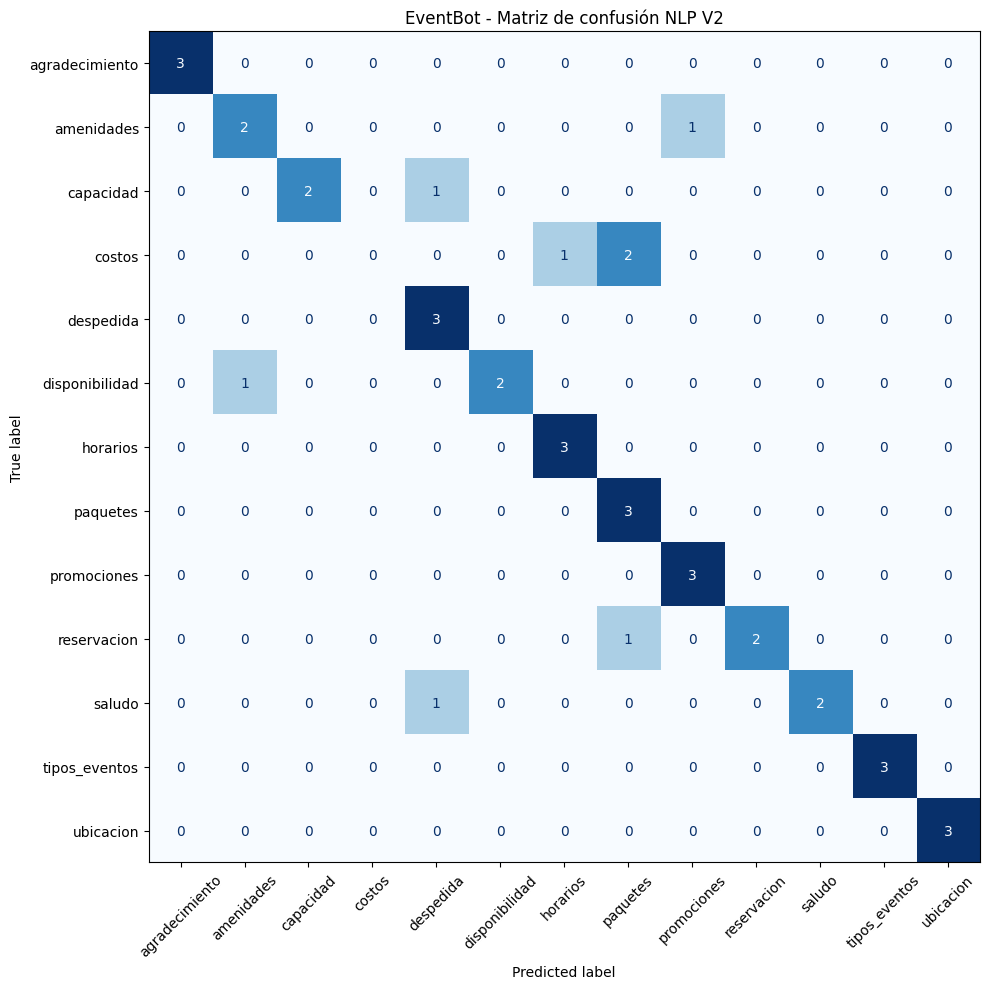

MODELO V2 Y EVIDENCIAS GUARDADOS
Modelo: /content/EventBot/modelos/clasificador_intenciones_v2.joblib

Archivos de resultados:
- comparacion_modelos_nlp.csv
- errores_clasificacion_nlp.csv
- errores_clasificacion_nlp_v2.csv
- evaluacion_nlp_inicial.csv
- evaluacion_nlp_v2.csv
- matriz_confusion_nlp.png
- matriz_confusion_nlp_v2.png
- metricas_nlp_inicial.json
- metricas_nlp_v2.json
- reporte_nlp_inicial.csv
- reporte_nlp_v2.csv


In [22]:

from pathlib import Path
import pandas as pd
import json
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ruta_base = Path("/content/EventBot")
ruta_resultados = ruta_base / "resultados/avance2"
ruta_modelos = ruta_base / "modelos"

ruta_resultados.mkdir(parents=True, exist_ok=True)
ruta_modelos.mkdir(parents=True, exist_ok=True)

# 1. Guardar modelo entrenado
ruta_modelo = ruta_modelos / "clasificador_intenciones_v2.joblib"

clasificador_v2.guardar_modelo(str(ruta_modelo))

# 2. Guardar reporte de clasificación
reporte_v2_df.to_csv(
    ruta_resultados / "reporte_nlp_v2.csv",
    encoding="utf-8-sig"
)

# 3. Guardar comparación de modelos
comparacion_modelos.to_csv(
    ruta_resultados / "comparacion_modelos_nlp.csv",
    index=False,
    encoding="utf-8-sig"
)

# 4. Guardar predicciones completas
evaluacion_v2 = pd.DataFrame({
    "consulta": X_test.values,
    "intencion_real": y_test.values,
    "intencion_predicha": predicciones_v2
})

evaluacion_v2["correcta"] = (
    evaluacion_v2["intencion_real"]
    == evaluacion_v2["intencion_predicha"]
)

evaluacion_v2.to_csv(
    ruta_resultados / "evaluacion_nlp_v2.csv",
    index=False,
    encoding="utf-8-sig"
)

# 5. Guardar errores
errores_v2.to_csv(
    ruta_resultados / "errores_clasificacion_nlp_v2.csv",
    index=False,
    encoding="utf-8-sig"
)

# 6. Guardar métricas generales
metricas_v2 = {
    "modelo": "TF-IDF + LinearSVC",
    "version": "V2",
    "consultas_entrenamiento": len(X_train),
    "consultas_prueba": len(X_test),
    "accuracy": float(accuracy_v2),
    "precision_macro": float(
        reporte_v2["macro avg"]["precision"]
    ),
    "recall_macro": float(
        reporte_v2["macro avg"]["recall"]
    ),
    "f1_macro": float(
        reporte_v2["macro avg"]["f1-score"]
    )
}

with open(
    ruta_resultados / "metricas_nlp_v2.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        metricas_v2,
        archivo,
        indent=4,
        ensure_ascii=False
    )

# 7. Generar matriz de confusión V2
fig, ax = plt.subplots(figsize=(13, 10))

ConfusionMatrixDisplay(
    confusion_matrix=matriz_v2,
    display_labels=etiquetas_v2
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("EventBot - Matriz de confusión NLP V2")
plt.tight_layout()

plt.savefig(
    ruta_resultados / "matriz_confusion_nlp_v2.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("MODELO V2 Y EVIDENCIAS GUARDADOS")
print("=" * 45)
print("Modelo:", ruta_modelo)

print("\nArchivos de resultados:")
for archivo in sorted(ruta_resultados.iterdir()):
    print("-", archivo.name)


In [23]:

import pandas as pd

consultas_nuevas = [
    ("Hola, necesito que me orientes", "saludo"),
    ("Buen día, quisiera hacer una consulta", "saludo"),
    ("Muchas gracias por aclarar mis dudas", "agradecimiento"),
    ("Te agradezco mucho la explicación", "agradecimiento"),
    ("Hasta luego, que estés bien", "despedida"),
    ("Nos comunicamos otro día", "despedida"),
    ("¿En qué calle se localiza el salón?", "ubicacion"),
    ("¿Me pueden enviar la dirección exacta?", "ubicacion"),
    ("¿Desde qué hora puedo visitarlos?", "horarios"),
    ("¿A qué hora dejan de atender?", "horarios"),
    ("¿Qué alternativas de paquetes ofrecen?", "paquetes"),
    ("¿Qué viene incluido en el plan Diamante?", "paquetes"),
    ("¿Cuánto tendría que pagar por la renta?", "costos"),
    ("¿Cuál es el precio total del evento?", "costos"),
    ("¿Tienen alguna rebaja actualmente?", "promociones"),
    ("¿Hay ofertas para contratar el salón?", "promociones"),
    ("¿Puedo elegir una fecha que esté libre?", "disponibilidad"),
    ("¿Tienen algún sábado sin ocupar?", "disponibilidad"),
    ("¿Qué debo hacer para contratar una fecha?", "reservacion"),
    ("¿Cómo puedo iniciar mi reservación?", "reservacion"),
    ("¿Cuál es el límite de personas permitido?", "capacidad"),
    ("¿Cuántos asistentes pueden entrar?", "capacidad"),
    ("¿El lugar cuenta con equipo de sonido?", "amenidades"),
    ("¿Disponen de aire acondicionado?", "amenidades"),
    ("¿Se pueden realizar fiestas de quince años?", "tipos_eventos"),
    ("¿Es posible celebrar una reunión empresarial?", "tipos_eventos")
]

df_nuevas = pd.DataFrame(
    consultas_nuevas,
    columns=["texto", "intencion"]
)

print("CONSULTAS NUEVAS:", len(df_nuevas))
print("INTENCIONES:", df_nuevas["intencion"].nunique())

display(df_nuevas.head())


CONSULTAS NUEVAS: 26
INTENCIONES: 13


,texto,intencion
0,"Hola, necesito que me orientes",saludo
1,"Buen día, quisiera hacer una consulta",saludo
2,Muchas gracias por aclarar mis dudas,agradecimiento
3,Te agradezco mucho la explicación,agradecimiento
4,"Hasta luego, que estés bien",despedida


In [24]:

from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# Verificar que las consultas sean distintas
# de las utilizadas anteriormente
consultas_anteriores = set(
    pd.concat(
        [datos_train["texto"], datos_test["texto"]]
    ).str.lower().str.strip()
)

assert set(
    df_nuevas["texto"].str.lower().str.strip()
).isdisjoint(consultas_anteriores), (
    "Existen consultas repetidas con los datasets anteriores"
)

# Realizar predicciones
predicciones_nuevas = clasificador_v2.pipeline.predict(
    df_nuevas["texto"]
)

df_nuevas["prediccion"] = predicciones_nuevas

df_nuevas["correcta"] = (
    df_nuevas["intencion"] == df_nuevas["prediccion"]
)

# Calcular metricas
accuracy_nuevo = accuracy_score(
    df_nuevas["intencion"],
    predicciones_nuevas
)

print("EVALUACION CON CONSULTAS NUEVAS")
print("=" * 45)
print("Total de consultas:", len(df_nuevas))
print("Accuracy:", round(accuracy_nuevo, 4))
print("Errores:", (~df_nuevas["correcta"]).sum())

print("\nREPORTE DE CLASIFICACION")
print(
    classification_report(
        df_nuevas["intencion"],
        predicciones_nuevas,
        zero_division=0
    )
)

print("\nCONSULTAS CLASIFICADAS INCORRECTAMENTE")

display(
    df_nuevas[
        ~df_nuevas["correcta"]
    ]
)

# Guardar evidencia
df_nuevas.to_csv(
    "/content/EventBot/resultados/avance2/"
    "evaluacion_consultas_nuevas.csv",
    index=False,
    encoding="utf-8-sig"
)


EVALUACION CON CONSULTAS NUEVAS
Total de consultas: 26
Accuracy: 1.0
Errores: 0

REPORTE DE CLASIFICACION
                precision    recall  f1-score   support

agradecimiento       1.00      1.00      1.00         2
    amenidades       1.00      1.00      1.00         2
     capacidad       1.00      1.00      1.00         2
        costos       1.00      1.00      1.00         2
     despedida       1.00      1.00      1.00         2
disponibilidad       1.00      1.00      1.00         2
      horarios       1.00      1.00      1.00         2
      paquetes       1.00      1.00      1.00         2
   promociones       1.00      1.00      1.00         2
   reservacion       1.00      1.00      1.00         2
        saludo       1.00      1.00      1.00         2
 tipos_eventos       1.00      1.00      1.00         2
     ubicacion       1.00      1.00      1.00         2

      accuracy                           1.00        26
     macro avg       1.00      1.00      1.00       

,texto,intencion,prediccion,correcta


In [25]:

import json
from pathlib import Path
from sklearn.metrics import classification_report

ruta_resultados = Path(
    "/content/EventBot/resultados/avance2"
)

reporte_nuevas = classification_report(
    df_nuevas["intencion"],
    df_nuevas["prediccion"],
    output_dict=True,
    zero_division=0
)

metricas_nuevas = {
    "modelo": "TF-IDF + LinearSVC V2",
    "tipo_evaluacion": "Consultas adicionales",
    "total_consultas": len(df_nuevas),
    "total_intenciones": df_nuevas["intencion"].nunique(),
    "accuracy": float(accuracy_nuevo),
    "precision_macro": float(
        reporte_nuevas["macro avg"]["precision"]
    ),
    "recall_macro": float(
        reporte_nuevas["macro avg"]["recall"]
    ),
    "f1_macro": float(
        reporte_nuevas["macro avg"]["f1-score"]
    ),
    "errores": int(
        (~df_nuevas["correcta"]).sum()
    )
}

ruta_archivo = (
    ruta_resultados /
    "metricas_consultas_nuevas.json"
)

with open(
    ruta_archivo,
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        metricas_nuevas,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("METRICAS ADICIONALES GUARDADAS")
print("Archivo:", ruta_archivo)
print("Accuracy:", metricas_nuevas["accuracy"])
print("F1-score:", metricas_nuevas["f1_macro"])


METRICAS ADICIONALES GUARDADAS
Archivo: /content/EventBot/resultados/avance2/metricas_consultas_nuevas.json
Accuracy: 1.0
F1-score: 1.0


In [26]:

from pathlib import Path

ruta_imagenes = Path(
    "/content/EventBot/data/imagenes"
)

categorias = [
    "boda",
    "xv_anos",
    "corporativo"
]

conjuntos = [
    "train",
    "val",
    "test"
]

for conjunto in conjuntos:
    for categoria in categorias:

        carpeta = ruta_imagenes / conjunto / categoria

        carpeta.mkdir(
            parents=True,
            exist_ok=True
        )

        print("Creada:", carpeta)

print("\nESTRUCTURA DEL DATASET CREADA CORRECTAMENTE")


Creada: /content/EventBot/data/imagenes/train/boda
Creada: /content/EventBot/data/imagenes/train/xv_anos
Creada: /content/EventBot/data/imagenes/train/corporativo
Creada: /content/EventBot/data/imagenes/val/boda
Creada: /content/EventBot/data/imagenes/val/xv_anos
Creada: /content/EventBot/data/imagenes/val/corporativo
Creada: /content/EventBot/data/imagenes/test/boda
Creada: /content/EventBot/data/imagenes/test/xv_anos
Creada: /content/EventBot/data/imagenes/test/corporativo

ESTRUCTURA DEL DATASET CREADA CORRECTAMENTE


In [27]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [28]:

from pathlib import Path

ruta_drive = Path(
    "/content/drive/MyDrive/EventBot_Imagenes"
)

categorias = ["boda", "xv_anos", "corporativo"]

print("VERIFICACIÓN DE CARPETAS EN GOOGLE DRIVE")
print("=" * 45)

for categoria in categorias:
    carpeta = ruta_drive / categoria

    if carpeta.exists():
        print(f"OK - {categoria}: carpeta encontrada")
    else:
        print(f"PENDIENTE - {categoria}: carpeta no encontrada")


VERIFICACIÓN DE CARPETAS EN GOOGLE DRIVE
OK - boda: carpeta encontrada
OK - xv_anos: carpeta encontrada
OK - corporativo: carpeta encontrada


## Componente visual - CNN con EfficientNetB0

### Objetivo

Implementar un modelo de clasificación de imágenes mediante
una red neuronal convolucional con transferencia de aprendizaje,
capaz de identificar tres tipos de eventos del Salón Destellos:

- Bodas
- Eventos corporativos
- XV años

Se utiliza EfficientNetB0 preentrenado con ImageNet,
adaptando su capa de clasificación a las tres categorías.

Este componente se integrará con EventBot para interpretar
fotografías y comunicar al usuario el tipo de evento
identificado de manera orientativa.


### Preparación del dataset visual

Se preparó un conjunto de 90 fotografías organizadas
en tres categorías equilibradas:

| Categoría | Entrenamiento | Validación | Prueba |
|---|---:|---:|---:|
| Boda | 20 | 5 | 5 |
| Corporativo | 20 | 5 | 5 |
| XV años | 20 | 5 | 5 |
| **Total** | **60** | **15** | **15** |

Se comprobó la integridad de los archivos y se eliminaron
del dataset los duplicados exactos detectados.
La revisión mediante hash perceptual no detectó pares
similares entre conjuntos bajo el umbral utilizado.

Las imágenes se almacenan en Google Drive y se
redimensionan a 224 x 224 píxeles durante su carga.

Limitación: el tamaño del dataset es reducido y las
fotografías de bodas y XV años pueden compartir
características visuales similares.


In [ ]:
import tensorflow as tf
from pathlib import Path
from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

ruta_dataset = Path(
    "/content/drive/MyDrive/EventBot_Dataset_CNN"
)

IMG_SIZE = (224, 224)
BATCH_SIZE = 8
SEED = 42
CLASES = ["boda", "corporativo", "xv_anos"]

def cargar_conjunto(nombre, mezclar=False):
    return tf.keras.utils.image_dataset_from_directory(
        ruta_dataset / nombre,
        labels="inferred",
        label_mode="categorical",
        class_names=CLASES,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=mezclar,
        seed=SEED if mezclar else None
    )

train_ds = cargar_conjunto("train", mezclar=True)
val_ds = cargar_conjunto("val")
test_ds = cargar_conjunto("test")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Dataset CNN cargado correctamente.")
print("Clases:", CLASES)


### Arquitectura y entrenamiento CNN

Se utiliza EfficientNetB0 con pesos preentrenados de
ImageNet y transferencia de aprendizaje.

La arquitectura incorpora:

- Aumento de datos durante el entrenamiento.
- EfficientNetB0 como extractor de características.
- GlobalAveragePooling2D.
- Dropout del 30 %.
- Capa Dense con tres salidas Softmax.

Durante la primera fase, se congelan las capas
preentrenadas y se entrena únicamente el clasificador
personalizado.

Se utiliza EarlyStopping y ModelCheckpoint para
conservar el modelo con menor pérdida de validación.


In [ ]:
# Aumento de datos
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(0.05, 0.05)
], name="data_augmentation")

# Modelo base preentrenado
modelo_base = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

modelo_base.trainable = False

# Arquitectura CNN
entradas = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(entradas)
x = modelo_base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30)(x)

salidas = tf.keras.layers.Dense(
    3,
    activation="softmax",
    name="clasificacion_eventos"
)(x)

modelo_cnn = tf.keras.Model(
    inputs=entradas,
    outputs=salidas,
    name="EventBot_EfficientNetB0"
)

modelo_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

modelo_cnn.summary()


In [ ]:
# Entrenamiento inicial de EfficientNetB0
ruta_modelos = Path(
    "/content/drive/MyDrive/EventBot_Modelos_CNN"
)
ruta_modelos.mkdir(parents=True, exist_ok=True)

ruta_mejor_modelo = (
    ruta_modelos / "efficientnetb0_mejor.keras"
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(ruta_mejor_modelo),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

historial_cnn = modelo_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks,
    verbose=1
)

print("Entrenamiento finalizado.")
print("Modelo guardado en:", ruta_mejor_modelo)


### Experimento de Fine-Tuning

Después del entrenamiento inicial se realizó un
experimento de ajuste fino utilizando EfficientNetB0.

Se descongelaron únicamente las últimas 20 capas,
manteniendo las capas BatchNormalization congeladas.

Se utilizó una tasa de aprendizaje de 0.00001 y
EarlyStopping para reducir el riesgo de sobreajuste.

**Resultados obtenidos:**

| Métrica | Modelo inicial | Fine-Tuning |
|---|---:|---:|
| Accuracy de validación | 53.33 % | 53.33 % |
| F1-score macro | 48.79 % | 48.79 % |
| Menor val_loss | 0.8667 | 0.8659 |

El Fine-Tuning no mejoró las métricas de clasificación.
Se conservó el modelo inicial como candidato final,
considerando su menor complejidad de entrenamiento.


In [ ]:
# Fine-Tuning de EfficientNetB0
# Ejecutar solo si se desea reproducir este experimento.

ruta_modelo_inicial = (
    ruta_modelos / "efficientnetb0_mejor.keras"
)

modelo_finetuning = tf.keras.models.load_model(
    ruta_modelo_inicial
)

base_finetuning = modelo_finetuning.get_layer(
    "efficientnetb0"
)

base_finetuning.trainable = True

# Ajustar solamente las últimas 20 capas
for capa in base_finetuning.layers[:-20]:
    capa.trainable = False

for capa in base_finetuning.layers:
    if isinstance(capa, tf.keras.layers.BatchNormalization):
        capa.trainable = False

modelo_finetuning.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

ruta_finetuning = (
    ruta_modelos / "efficientnetb0_finetuning.keras"
)

callbacks_finetuning = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(ruta_finetuning),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

historial_finetuning = modelo_finetuning.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_finetuning,
    verbose=1
)

print("Fine-Tuning completado.")


### Evaluación final del modelo CNN

Se evaluó el modelo EfficientNetB0 inicial utilizando
15 imágenes de prueba independientes del entrenamiento
y de la selección del modelo.

**Resultados:**

| Métrica | Resultado |
|---|---:|
| Accuracy | 66.67 % |
| Precision macro | 69.05 % |
| Recall macro | 66.67 % |
| F1-score macro | 66.67 % |

**Desempeño por categoría:**

| Categoría | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Boda | 57.14 % | 80.00 % | 66.67 % |
| Corporativo | 75.00 % | 60.00 % | 66.67 % |
| XV años | 75.00 % | 60.00 % | 66.67 % |

El modelo clasificó correctamente 10 de 15 imágenes.

La matriz de confusión mostró errores entre las
categorías boda, corporativo y XV años.

**Limitaciones:** el conjunto de prueba es pequeño
y cada predicción representa aproximadamente 6.67
puntos porcentuales de accuracy. Por ello, estos
resultados son preliminares y no garantizan el mismo
desempeño ante fotografías nuevas.


In [ ]:
# Evaluación final del modelo CNN
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

modelo_final_cnn = tf.keras.models.load_model(
    ruta_modelos / "efficientnetb0_mejor.keras"
)

y_real_test = np.concatenate([
    np.argmax(etiquetas.numpy(), axis=1)
    for imagenes, etiquetas in test_ds
])

probabilidades_test = modelo_final_cnn.predict(
    test_ds, verbose=0
)

y_pred_test = np.argmax(probabilidades_test, axis=1)

print("Accuracy:",
      accuracy_score(y_real_test, y_pred_test))

print("Precision macro:",
      precision_score(
          y_real_test, y_pred_test,
          average="macro", zero_division=0
      ))

print("Recall macro:",
      recall_score(
          y_real_test, y_pred_test,
          average="macro", zero_division=0
      ))

print("F1 macro:",
      f1_score(
          y_real_test, y_pred_test,
          average="macro", zero_division=0
      ))

print("\nReporte por categoría:")
print(classification_report(
    y_real_test, y_pred_test,
    labels=[0, 1, 2],
    target_names=CLASES,
    zero_division=0
))

matriz = confusion_matrix(
    y_real_test, y_pred_test,
    labels=[0, 1, 2]
)

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=CLASES
).plot(cmap="Blues", values_format="d")

plt.title("EventBot - Matriz de confusión CNN")
plt.show()


### Integración del componente NLP y CNN

Se integró el clasificador visual EfficientNetB0
con la clase principal `EventBot`.

El sistema conserva sus funcionalidades conversacionales
y agrega `responder_imagen()` para interpretar fotografías.

El método permite:
1. Recibir la ruta de una fotografía.
2. Ejecutar el clasificador visual.
3. Comunicar la categoría estimada en lenguaje natural.
4. Registrar la interacción en el historial.

**Prueba realizada:**

- Consulta: ¿Qué paquetes ofrecen?
- Imagen: `FotoBoda1.jpg`
- Clasificación: boda (puntuación 61.1 %).
- Interacciones registradas: 2.
- Integración funcional: exitosa.

La clasificación es orientativa debido a las
limitaciones de precisión del modelo CNN.


In [ ]:
# Prueba de integración NLP + CNN
import sys
from pathlib import Path

ruta_proyecto = "/content/EventBot_GitHub"
if ruta_proyecto not in sys.path:
    sys.path.insert(0, ruta_proyecto)

from src.eventbot import EventBot

bot = EventBot(
    ruta_proyecto=ruta_proyecto,
    ruta_modelo_cnn=(
        "/content/drive/MyDrive/EventBot_Modelos_CNN/"
        "efficientnetb0_mejor.keras"
    )
)

print(bot.iniciar_sesion())

print("\nCONSULTA DE TEXTO:")
print(bot.responder("¿Qué paquetes ofrecen?"))

print("\nCONSULTA VISUAL:")
print(bot.responder_imagen(
    "/content/drive/MyDrive/EventBot_Dataset_CNN/"
    "test/boda/FotoBoda1.jpg"
))

historial = bot.obtener_historial()
assert len(historial) == 2
assert historial[1]["intencion"] == "clasificacion_visual"

print("\nINTEGRACIÓN NLP + CNN VERIFICADA")
